In [1]:
# Checkpoint 2: Reproduction of TROP2 paper analysis
# Data: Processed E-MTAB-16585 epithelial cells
# Goal: (a) TACSTD2 / LGR5 expression across cell states
#       (b) donor-level cell-state proportions (LGR5+, TROP2+, both, or neither)
# Show that our results look like in comparison to the paper and explain differences
# Show the gene-dependency model that we created

import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import json, requests

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [ ]:
# ============================================================
# REPRODUCTION STATUS (Checkpoint 2, paper analysis)
# Task per instructions: reproduce TACSTD2/LGR5 expression and donor
# cell-state proportions from processed E-MTAB-16585 epithelial data.
# Must record: transformations, annotations, donor grouping, any subset used.
# ============================================================

# ---------- WHAT WE HAVE DONE ----------
# 1. Loaded the processed epithelial files (biobank_subcut_epi_*) from the
#    E-MTAB-16585 download: log1p expression, metadata, and UMAP coordinates.
# 2. Read only TACSTD2 and LGR5 from the 1.3 GB log1p file (streamed line by
#    line) instead of loading all 27,111 genes. This keeps memory low.
# 3. Merged expression, metadata, and UMAP into one table, one row per cell.
#    Barcodes matched in all three files (10,135 of 10,135).
# 4. Computed output (a): mean expression and % of cells expressing each gene,
#    per cluster.
# 5. Computed output (b): proportion of each donor's cells in each cluster.
# 6. [ ] Found the real cell-state names (use supplementary table 3
# or the paper's repo). If none exist, say so in the
#     report and label clusters descriptively as OUR OWN labels.
# [ ] Make and save the figures: UMAP (clusters and genes), violin plots
#     per cluster, stacked bars of donor proportions.

# ---------- WHAT WE KNOW (needed for the report) ----------
# Data:           10,135 epithelial cells, 7 donors, 24 samples, 8 leiden clusters (0-7)
# Transformation: expression is the provided log1p layer. We applied no extra
#                 normalization of our own.
# Subset:         none. All 10,135 cells are used; only the two genes are read.
# Donor grouping: by donor_id, pooling each donor's samples (24 samples -> 7 donors).
# Annotation:     leiden cluster numbers only. No cell-state names in the
#                 metadata files, so cell_state is currently a placeholder.
# Donor sizes:    uneven. HD4254 has 2,580 cells, HD4277 has only 192 (one
#                 sample). Proportions for small donors are noisy.
# Expression:     sparse. TACSTD2 > 0 in 23% of cells, LGR5 > 0 in 53%.
# Pattern:        LGR5 is highest in cluster 0 (mean 1.77, 85% of cells) and
#                 TACSTD2 is highest in cluster 3 (mean 0.47, 46%), so the two
#                 genes mark different clusters. Check against the paper's
#                 figure before claiming a match.

# ---------- WHAT WE STILL HAVE TO DO ----------
# [ ] Save the tables and figures to results/ (needed for the report and video).
# [ ] Step 6: compare our outputs with the paper's Figure 1 and note
#     differences (clusters vs named states, which dataset the panel uses,
#     imputed vs raw expression).
# [ ] Check that batch is not confounded with donor (crosstab of donor_id and batch).
# [ ] Write the reproduction section of the report (data, transformations,
#     annotation, donor grouping, subset, results, limitations).
# [ ]

## What We Have vs. What We Still Need

| Have | Still need |
|---|---|
| The downloaded `.txt` data files | Cluster-to-state names |
| Our `Checkpoint2_model_reproduction` notebook with working cells | Supplementary Table 3 (download it from the article page) |
| The paper's text (methods and legends) | A look at the Fig. 1 images to compare |
| Tables of expression per cluster and donor proportions | Saved figures and tables in `results/` |
| A clear idea of the paper's composition method | The marker-based donor table (Cell 9) |

In [3]:
# Reviewing how our file is laid out to assemble AnnData
# Only the first four lines

#folder = r"C:\Users\joann\OneDrive\Documents\GitHub\Tumor-Surface-Target-Prioritization\model_reproduction_data"
folder = "/content"

for f in ["biobank_subcut_epi_counts.txt",
          "biobank_subcut_epi_counts_log1p.txt",
          "biobank_subcut_epi_features.txt",
          "biobank_subcut_epi_umap.txt"]:
    path = os.path.join(folder, f)
    print("=====", f, "|", round(os.path.getsize(path) / 1e6, 1), "MB")
    with open(path, encoding="utf-8") as fh:
        for _ in range(4):
            print(fh.readline()[:200].rstrip())
    print()

===== biobank_subcut_epi_counts.txt | 1101.4 MB
barcode	AAACCCACAAGCGGAT-1-0	AAAGGTAGTGTCATTG-1-0	AAAGTCCCAACAACAA-1-0	AACCATGCAATAGTCC-1-0	AACCATGGTGTAAACA-1-0	AACCCAACAGCTTTGA-1-0	AACGAAAAGCCTGTCG-1-0	AACGAAATCCTACTGC-1-0	AAGACTCGTGTGTTTG-1-0	AAG
A1BG	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0
A1BG-AS1	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0
A1CF	0.0	0.0	0.0	0.0	1.0	0.0	1.0	1.0	3.0	0.0	0.0	1.0	0.0	0.0	0.0	0.0	1.0	0.0	2.0	0.0	0.0	1.0	0.0	2.0	0.0	0.0	0.0	2.0	1.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	1.0	0.0	1.0	0.0	1.0	0.0	0.0	1.0	0.0

===== biobank_subcut_epi_counts_log1p.txt | 1335.1 MB
barcode	AAACCCACAAGCGGAT-1-0	AAAGGTAGTGTCATTG-1-0	AAAGTCCCAACAACAA-1-0	AACCATGCAATAGTCC-1-0	A

In [4]:
# Loading in the txt files
folder = r"C:\Users\joann\OneDrive\Documents\GitHub\Tumor-Surface-Target-Prioritization\model_reproduction_data"
folder = "/content"

LOG1P_FILE = os.path.join(folder, "biobank_subcut_epi_counts_log1p.txt")
META_FILE  = os.path.join(folder, "biobank_subcut_epi_metadata.txt")
UMAP_FILE  = os.path.join(folder, "biobank_subcut_epi_umap.txt")
GENES = ["TACSTD2", "LGR5"]
# Tested that they all three loaded in

In [7]:
# Read in the two primary genes TACSTD2 and LGR5

def read_gene_rows(path, genes):
    found = {}
    with open(path, encoding="utf-8") as fh:
        header = fh.readline().rstrip("\n").split("\t")
        barcodes = header[1:]                      # first field is the word 'barcode'
        for line in fh:
            name, _, rest = line.partition("\t")   # split off the gene name
            if name in genes:
                found[name] = np.array(rest.rstrip("\n").split("\t"), dtype=np.float32)
                if len(found) == len(genes):
                    break
    return barcodes, found

barcodes, expr = read_gene_rows(LOG1P_FILE, GENES)

# Ensuring that both genes were found and each gene has a value for each cell
print("cells in matrix:", len(barcodes))
for g in GENES:
    print(g, "found" if g in expr else "MISSING", "| values:", len(expr.get(g, [])))

cells in matrix: 10135
TACSTD2 found | values: 10135
LGR5 found | values: 10135


In [9]:
# Build a table where each cell column has a donor, cluster,
# UMAP position, and TACSTD2/LGR5 expression row

meta = pd.read_csv(META_FILE, sep=None, engine="python").set_index("barcode")
umap = pd.read_csv(UMAP_FILE, sep="\t", index_col=0).T     # flip so cells are rows

# Making sure that all three barcodes match one another
print("barcodes matching metadata:", pd.Index(barcodes).isin(meta.index).sum(), "of", len(barcodes))
print("barcodes matching UMAP:    ", pd.Index(barcodes).isin(umap.index).sum(), "of", len(barcodes))

cells = meta.reindex(barcodes).join(umap.reindex(barcodes))
for g in GENES:
    cells[g] = expr[g]
print(cells.head())

barcodes matching metadata: 10135 of 10135
barcodes matching UMAP:     10135 of 10135
                           sample_id donor_id library_id  batch  leiden  \
barcode                                                                   
AAACCCACAAGCGGAT-1-0  HD4277_1277808   HD4277        S01      0       2   
AAAGGTAGTGTCATTG-1-0  HD4277_1277808   HD4277        S01      0       3   
AAAGTCCCAACAACAA-1-0  HD4277_1277808   HD4277        S01      0       0   
AACCATGCAATAGTCC-1-0  HD4277_1277808   HD4277        S01      0       3   
AACCATGGTGTAAACA-1-0  HD4277_1277808   HD4277        S01      0       0   

                        UMAP_1    UMAP_2   TACSTD2      LGR5  
barcode                                                       
AAACCCACAAGCGGAT-1-0  6.987477 -0.653591  0.000000  0.000000  
AAAGGTAGTGTCATTG-1-0  6.504561  6.719910  0.507988  0.000000  
AAAGTCCCAACAACAA-1-0  1.198617  3.391422  0.000000  0.777196  
AACCATGCAATAGTCC-1-0  3.492436  2.822797  0.711991  0.000000  
AACCATGGTG

In [10]:
# Checking donors, clusters, and the genes

print(cells["donor_id"].nunique(), "donors |", cells["sample_id"].nunique(), "samples")
print(cells["donor_id"].value_counts(), "\n")
print(cells["leiden"].value_counts().sort_index(), "\n")
print(pd.crosstab(cells["donor_id"], cells["sample_id"]).head(15), "\n")
print(cells[GENES].describe())
print("fraction of cells with TACSTD2 > 0:", (cells["TACSTD2"] > 0).mean())
print("fraction of cells with LGR5 > 0:   ", (cells["LGR5"] > 0).mean())

7 donors | 24 samples
donor_id
HD4254    2580
HD4272    2108
HD4236    1850
HD4246    1717
HD4362    1017
HD4309     671
HD4277     192
Name: count, dtype: int64 

leiden
0    2194
1    1877
2    1557
3    1520
4    1147
5     808
6     791
7     241
Name: count, dtype: int64 

sample_id  HD4236_1327494  HD4236_1327502  HD4236_1327504  HD4236_1327505  \
donor_id                                                                    
HD4236                503             249             425             212   
HD4246                  0               0               0               0   
HD4254                  0               0               0               0   
HD4272                  0               0               0               0   
HD4277                  0               0               0               0   
HD4309                  0               0               0               0   
HD4362                  0               0               0               0   

sample_id  HD4236_1327506  

In [14]:
#cluster names based on Fig 1.f
cell_state_mapping = {
    "0": "ISC",
    "1": "revSC",
    "2": "Ribosomal ISC",
    "3": "Fetal/HRC",
    "4": "HRC",
    "5": "Proliferation ISC",
    "6": "Proliferation",
    "7": "DTP"
}

# Looking at outputs a and b for both genes by cluster

cells["cell_state"] = cells["leiden"].astype(str).map(cell_state_mapping)

# (a) mean expression and fraction of cells expressing, per cluster
expr_by_state = cells.groupby("cell_state")[GENES].agg(["mean", lambda s: (s > 0).mean()])
expr_by_state.columns = ["TACSTD2_mean", "TACSTD2_frac", "LGR5_mean", "LGR5_frac"]
print(expr_by_state.round(3))

# (b) donor-level proportions: for each donor, the share of cells in each cluster
props = pd.crosstab(cells["donor_id"], cells["cell_state"], normalize="index")
print(props.round(3))

                   TACSTD2_mean  TACSTD2_frac  LGR5_mean  LGR5_frac
cell_state                                                         
DTP                       0.024         0.029      0.578      0.373
Fetal/HRC                 0.471         0.461      0.551      0.449
HRC                       0.385         0.326      0.205      0.188
ISC                       0.034         0.057      1.771      0.847
Proliferation             0.359         0.381      0.382      0.413
Proliferation ISC         0.271         0.303      0.762      0.531
Ribosomal ISC             0.177         0.181      0.964      0.593
revSC                     0.191         0.145      0.826      0.470
cell_state    DTP  Fetal/HRC    HRC    ISC  Proliferation  Proliferation ISC  \
donor_id                                                                       
HD4236      0.005      0.267  0.039  0.234          0.115              0.090   
HD4246      0.000      0.151  0.232  0.002          0.118              0.132   


In [24]:
os.makedirs("results", exist_ok=True)

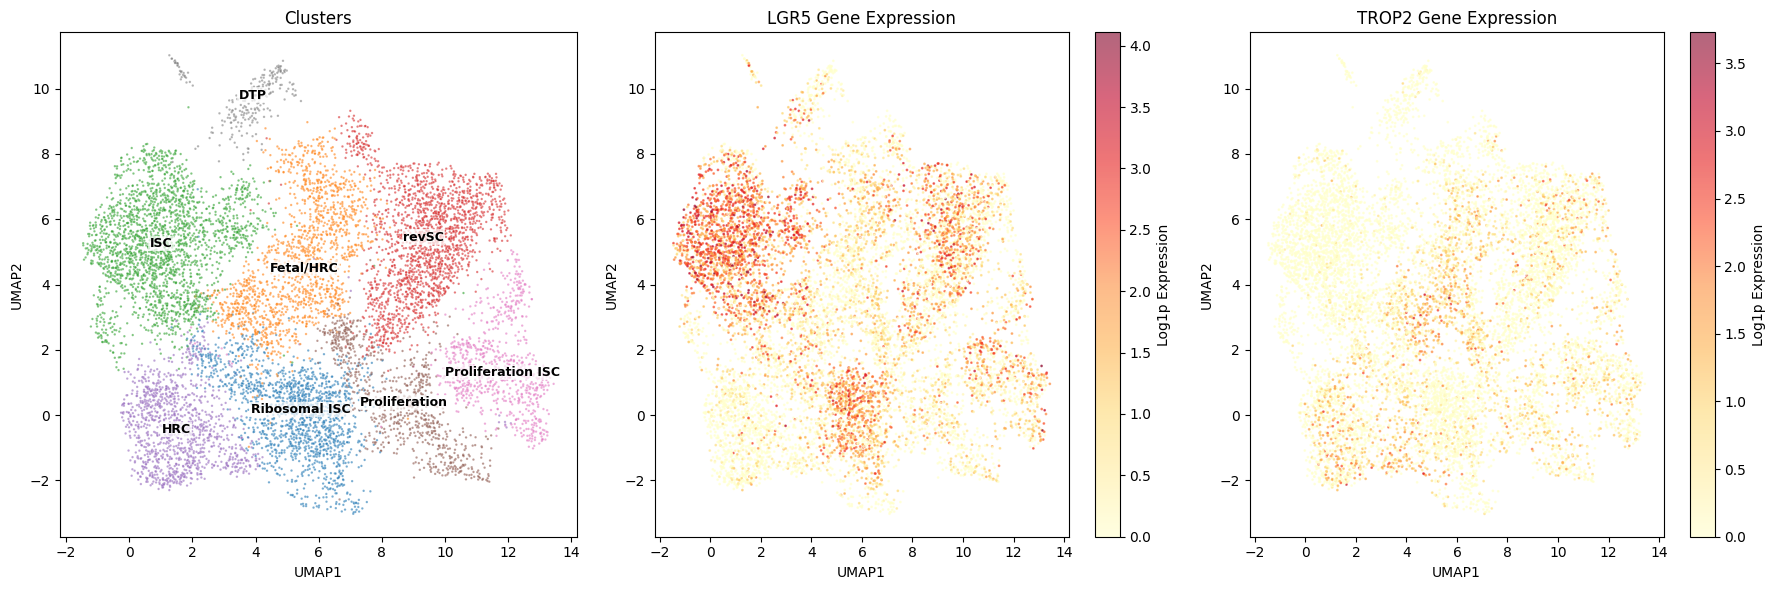

In [25]:
#utilized chatGPT edu figure out how to format names of each cluster on
#the figure rather than use a legend to make it look like Fig 1.f in paper
#and used it to figure out how to get the right colors for the gene plots to match paper
#UMAP (clusters and genes figure) Plot
#clusters
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
sns.scatterplot(data=cells, x="UMAP_1", y="UMAP_2", hue="cell_state",
                palette="tab10", s=3, alpha=0.6, ax=axes[0], legend = False)
axes[0].set_title("Clusters")
axes[0].set_xlabel("UMAP1")
axes[0].set_ylabel("UMAP2")

for state in cells["cell_state"].dropna().unique():
    state_coords = cells[cells["cell_state"] == state][["UMAP_1", "UMAP_2"]].median()
    axes[0].text(state_coords["UMAP_1"], state_coords["UMAP_2"], state,
                 fontsize=9, weight="bold", color="black",
                 bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1),
                 ha="center", va="center")

#LGR5 genes
sc_lgr5 = axes[1].scatter(cells["UMAP_1"], cells["UMAP_2"], c=cells["LGR5"],
                         cmap="YlOrRd", s=1, alpha=0.6)
fig.colorbar(sc_lgr5, ax=axes[1], label="Log1p Expression")
axes[1].set_title("LGR5 Gene Expression")
axes[1].set_xlabel("UMAP1")
axes[1].set_ylabel("UMAP2")

#TROP2 genes
sc_trop2 = axes[2].scatter(cells["UMAP_1"], cells["UMAP_2"], c=cells["TACSTD2"],
                          cmap="YlOrRd", s=1, alpha=0.6)
fig.colorbar(sc_trop2, ax=axes[2], label="Log1p Expression")
axes[2].set_title("TROP2 Gene Expression")
axes[2].set_xlabel("UMAP1")
axes[2].set_ylabel("UMAP2")

plt.tight_layout()
plt.savefig("results/umap_expression_and_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

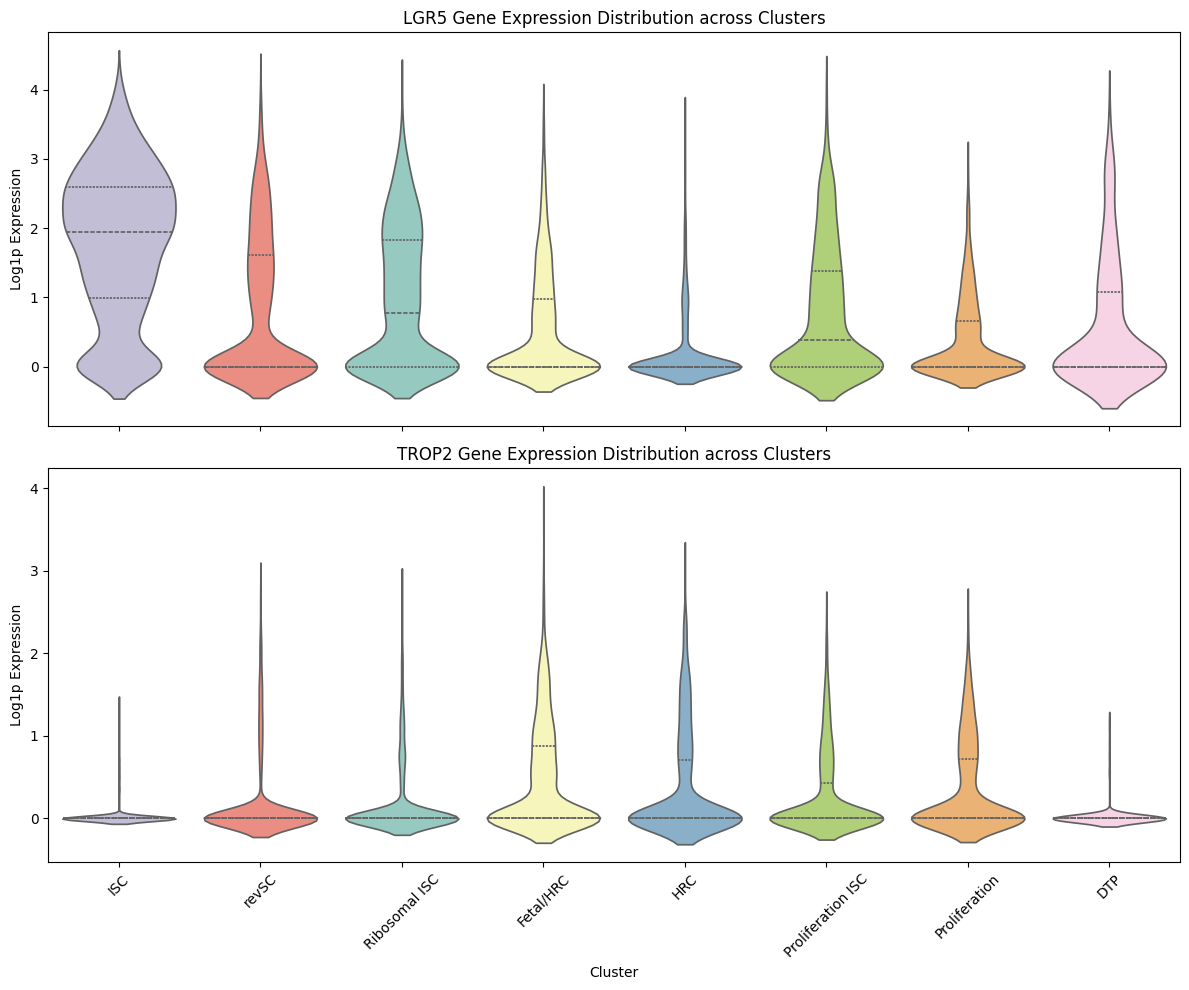

In [26]:
#violin plots per cluster
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

cluster_order = ["ISC", "revSC", "Ribosomal ISC", "Fetal/HRC", "HRC", "Proliferation ISC", "Proliferation", "DTP"]

sns.violinplot(data=cells, x="cell_state", y="LGR5", ax=axes[0],
               hue="cell_state", palette="Set3", order=cluster_order, inner="quartile")
axes[0].set_title("LGR5 Gene Expression Distribution across Clusters")
axes[0].set_ylabel("Log1p Expression")
axes[0].set_xlabel("")

sns.violinplot(data=cells, x="cell_state", y="TACSTD2", ax=axes[1],
               hue="cell_state", palette="Set3", order=cluster_order, inner="quartile")
axes[1].set_title("TROP2 Gene Expression Distribution across Clusters")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Log1p Expression")

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("results/violin_expression_by_state.png", dpi=300, bbox_inches="tight")
plt.show()

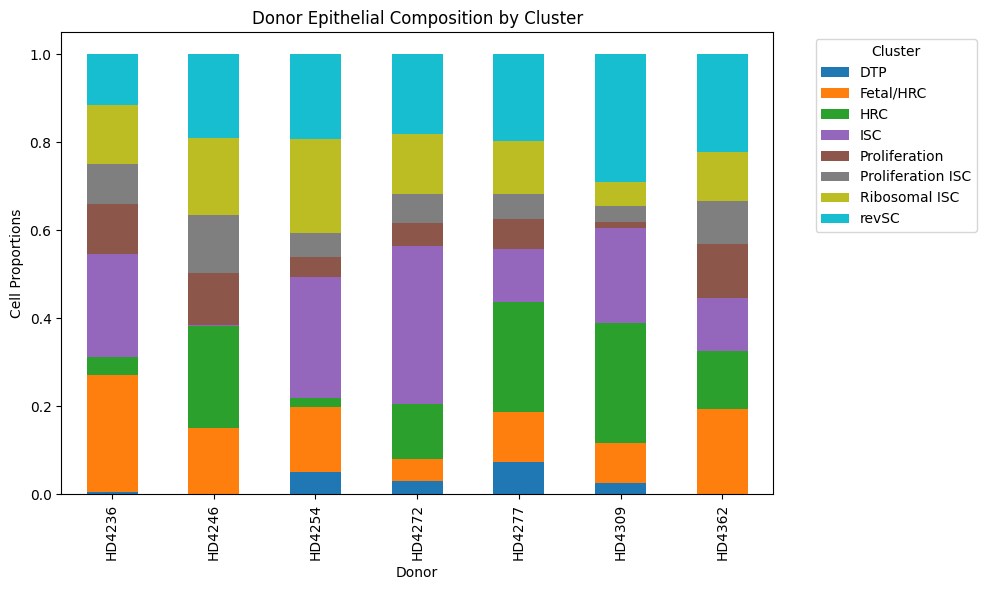

In [27]:
#stacked bars of donor proportions
donor_proportions = pd.crosstab(cells["donor_id"], cells["cell_state"], normalize="index")

ax = donor_proportions.plot(kind="bar", stacked = True, figsize = (10,6), colormap = "tab10")
plt.title("Donor Epithelial Composition by Cluster")
plt.ylabel("Cell Proportions")
plt.xlabel("Donor")
plt.legend(title="Cluster",bbox_to_anchor=(1.05,1), loc="upper left")
plt.tight_layout()
plt.savefig("results/donor_proportions_stacked_bar.png", dpi=300, bbox_inches="tight")
plt.show()